# Transfer Pricing Benchmarking Study: TNMM Walkthrough

**Method:** Transactional Net Margin Method (TNMM)
**Industry:** IT / Business Process Outsourcing Services
**Prepared as:** an educational methodology demonstration (see disclaimer at the end)

This notebook walks through a complete comparable-company benchmarking analysis,
end to end, exactly as an economist would perform one for a TNMM study under the
OECD Transfer Pricing Guidelines and U.S. Treas. Reg. §1.482-5 — except that every
data point comes from free public sources (Yahoo Finance) rather than a licensed
commercial database, and the "tested party" and intercompany loan are fictional,
invented purely to illustrate the mechanics.

Each section below explains **what** is being done and **why**, in transfer
pricing terms, before showing the code and its output. If you are reviewing this
as a TP professional rather than a developer, you can read the markdown text and
the printed tables/outputs and skip the code itself.

## 1. What TNMM Is, in Brief

Under the arm's length principle, transactions between related parties should be
priced as if the parties were independent. The **Transactional Net Margin Method**
tests this indirectly: rather than comparing prices line by line, it compares the
**net profit margin** (a "Profit Level Indicator", or PLI) that the tested party
earned on its controlled transactions to the margins earned by **independent
companies performing similar functions** — the "comparable set". If the tested
party's margin falls within the range of outcomes the comparables produced, its
result is considered consistent with the arm's length standard.

TNMM is popular in practice because it is more forgiving of product- and
market-level differences than a price-based method like CUP — what matters is
that the *functions performed, assets used, and risks assumed* are similar, not
that the exact goods or services are identical. That makes it well suited to
routine service providers (like an offshore IT delivery center), which is the
fact pattern this notebook builds around.

In [1]:
import os
import sys
from pathlib import Path

# Make the src/ package importable, and set the working directory to the
# project root, when running this notebook directly from the notebooks/
# directory -- so relative paths (data/, output/) resolve the same way
# they do everywhere else in this project (scripts, tests), and so the
# committed data/ cache is actually found instead of triggering a fresh
# live pull.
project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent
os.chdir(project_root)
sys.path.insert(0, str(project_root / "src"))

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

from tp_benchmarking.data_pull import pull_comp_set, get_pull_date, CANDIDATE_TICKERS
from tp_benchmarking.screening import run_comparability_screens
from tp_benchmarking.pli_calculations import compute_annual_plis, compute_weighted_average_plis
from tp_benchmarking.benchmarking import (
    compute_arms_length_range,
    assess_position,
    compute_primary_adjustment,
    HYPOTHETICAL_TESTED_PARTY,
)
from tp_benchmarking.cup import benchmark_loan_interest_rate, HYPOTHETICAL_INTERCOMPANY_LOAN
from tp_benchmarking.report import ReportInputs, TnmmReportInputs, write_report

print(f"Candidate comparables: {CANDIDATE_TICKERS}")

Candidate comparables: ['EPAM', 'GLOB', 'DAVA', 'GDYN', 'G', 'EXLS', 'CTSH', 'INFY', 'WIT', 'DXC']


## 2. Data Sourcing

A real TNMM study would license comparable-company financial data from a
commercial database (S&P Capital IQ, Moody's Orbis/Bureau van Dijk, RoyaltyStat,
etc.), which provides standardized financials, SIC/NAICS coding, and — critically
— related-party revenue disclosures. This project cannot use those, so it
substitutes `yfinance` (a free wrapper around Yahoo Finance) as a proxy data
source. That substitution is one of this project's central limitations and is
called out wherever it matters below.

The candidate set is ten independent, publicly listed IT/BPO services companies.
It was assembled by hand from public knowledge of the industry (not an automated
SIC-code database query, since no free one is available at the needed
granularity), deliberately excluding diversified mega-caps (e.g. Accenture, whose
~$65bn revenue and every-industry-vertical business mix would be a poor functional
match for a mid-size offshore delivery entity) and companies no longer
independently public (WNS Global Services was acquired by Capgemini in 2025).

The cell below pulls (or loads a cached, dated snapshot of) four fiscal years of
income-statement data and company profile data for each candidate.

In [2]:
raw_comp_set = pull_comp_set()  # loads the committed data/ snapshot by default
pull_date = get_pull_date()
print(f"Data snapshot as of: {pull_date}")
print(f"Rows (company-years): {len(raw_comp_set)}")
raw_comp_set.sort_values(["ticker", "fiscal_year_end"], ascending=[True, False]).head(12)

Data snapshot as of: 2026-09-18
Rows (company-years): 40


,ticker,fiscal_year_end,total_revenue,operating_income,gross_profit,operating_expense,cost_of_revenue,company_name,sector,industry,market_cap,currency,financial_currency,fx_rate_to_usd,total_revenue_usd
24,CTSH,2025-12-31,2.110800e+10,3.327000e+09,7.117000e+09,3.790000e+09,1.399100e+10,Cognizant Technology Solutions,Technology,Information Technology Services,27873488896,USD,USD,1.000000,2.110800e+10
25,CTSH,2024-12-31,1.973600e+10,3.026000e+09,6.778000e+09,3.752000e+09,1.295800e+10,Cognizant Technology Solutions,Technology,Information Technology Services,27873488896,USD,USD,1.000000,1.973600e+10
26,CTSH,2023-12-31,1.935300e+10,2.918000e+09,6.689000e+09,3.771000e+09,1.266400e+10,Cognizant Technology Solutions,Technology,Information Technology Services,27873488896,USD,USD,1.000000,1.935300e+10
27,CTSH,2022-12-31,1.942800e+10,2.968000e+09,6.980000e+09,4.012000e+09,1.244800e+10,Cognizant Technology Solutions,Technology,Information Technology Services,27873488896,USD,USD,1.000000,1.942800e+10
8,DAVA,2025-06-30,7.722550e+08,3.150700e+07,1.937020e+08,1.621950e+08,5.785530e+08,Endava plc,Technology,Software - Infrastructure,155357584,USD,GBP,1.334757,1.030773e+09
9,DAVA,2024-06-30,7.407560e+08,2.014000e+07,1.797080e+08,1.595680e+08,5.610480e+08,Endava plc,Technology,Software - Infrastructure,155357584,USD,GBP,1.334757,9.887293e+08
10,DAVA,2023-06-30,7.947330e+08,1.128450e+08,2.640770e+08,1.512320e+08,5.306560e+08,Endava plc,Technology,Software - Infrastructure,155357584,USD,GBP,1.334757,1.060776e+09
11,DAVA,2022-06-30,6.547570e+08,9.538400e+07,2.179310e+08,1.225470e+08,4.368260e+08,Endava plc,Technology,Software - Infrastructure,155357584,USD,GBP,1.334757,8.739415e+08
36,DXC,2026-03-31,1.264400e+10,3.000000e+08,3.031000e+09,2.731000e+09,9.613000e+09,DXC Technology Company,Technology,Information Technology Services,1827868160,USD,USD,1.000000,1.264400e+10
37,DXC,2025-03-31,1.287100e+10,6.980000e+08,3.101000e+09,2.403000e+09,9.770000e+09,DXC Technology Company,Technology,Information Technology Services,1827868160,USD,USD,1.000000,1.287100e+10


**Note on fiscal year ends and currency.** Not every comparable shares a December
fiscal year end — Infosys and Wipro report on an April-March fiscal year, and
Endava on a July-June fiscal year — and Wipro reports its financials in INR while
Endava reports in GBP (everyone else reports in USD). A real study would either
align periods more precisely or note the mismatch; here, each comparable's own
fiscal years are used as reported. Currency does **not** distort the PLIs
themselves, since every PLI is a ratio of two line items from the *same*
company's *same* statement (see Section 4) — it only matters for the
revenue-floor screen below, which needs a common currency to compare companies
against one another. That screen uses a spot FX conversion (see
`data_pull.get_fx_rate_to_usd`), itself a simplification versus using
period-matched average FX rates.

## 3. Comparability Screens

This is the step that turns a *candidate list* into a *comparable set* — and the
step a reviewing economist or tax authority scrutinizes most closely, because
every inclusion or exclusion decision needs a stated, defensible reason. Five
screens are applied, mirroring standard TNMM practice:

1. **Industry / functional classification** — a proxy for a SIC/NAICS code
   match. Endava is worth calling out specifically: Yahoo Finance tags it
   "Software - Infrastructure", not "Information Technology Services", but
   Endava's own public filings describe a functionally comparable IT/software
   engineering services business. It is retained based on a documented manual
   override — exactly the kind of automated-screen-plus-qualitative-review step
   a real comparable search performs.
2. **Minimum revenue threshold** ($50M average annual USD-equivalent revenue) —
   filters out shell companies/micro-caps whose margins would be noise-dominated.
3. **Persistent operating losses** — excluded if a comparable posted an
   operating loss in a *majority* of its available fiscal years (not merely
   "any" loss year — an isolated bad year doesn't disqualify a comparable per
   OECD Guidelines para 3.64, but a sustained pattern does).
4. **Significant related-party revenue** — **cannot be evaluated** with public
   data. This is disclosed explicitly as a limitation rather than silently
   skipped: a company whose reported margin was substantially earned on
   related-party transactions would not be a valid comparable, and this tool has
   no way to check for that.
5. **M&A-distorted years** — a >30% year-over-year revenue swing flags that
   *single fiscal year* (not the whole company) as a possible acquisition/
   divestiture distortion, excluding it from the multi-year weighted average.

In [3]:
screening = run_comparability_screens(raw_comp_set)

screening_log_cols = [
    "ticker", "company_name", "industry", "industry_screen_pass",
    "avg_annual_revenue_usd", "revenue_screen_pass",
    "loss_years", "total_years", "loss_year_screen_pass",
    "included", "exclusion_reason",
]
screening.company_log[screening_log_cols]

,ticker,company_name,industry,industry_screen_pass,avg_annual_revenue_usd,revenue_screen_pass,loss_years,total_years,loss_year_screen_pass,included,exclusion_reason
0,EPAM,"EPAM Systems, Inc.",Information Technology Services,True,4.925058e+09,True,0,4,True,True,
1,GLOB,Globant S.A.,Information Technology Services,True,2.186687e+09,True,0,4,True,True,
2,DAVA,Endava plc,Software - Infrastructure,True,9.885548e+08,True,0,4,True,True,
3,GDYN,"Grid Dynamics Holdings, Inc.",Information Technology Services,True,3.464475e+08,True,3,4,False,False,Operating loss in 3 of 4 evaluated fiscal year...
4,G,Genpact Limited,Information Technology Services,True,4.673770e+09,True,0,4,True,True,
5,EXLS,"ExlService Holdings, Inc.",Information Technology Services,True,1.742191e+09,True,0,4,True,True,
6,CTSH,Cognizant Technology Solutions,Information Technology Services,True,1.990625e+10,True,0,4,True,True,
7,INFY,Infosys Limited,Information Technology Services,True,1.905225e+10,True,0,4,True,True,
8,WIT,Wipro Limited,Information Technology Services,True,9.439521e+09,True,0,4,True,True,
9,DXC,DXC Technology Company,Information Technology Services,True,1.340300e+10,True,2,4,True,True,


In [4]:
print(f"Final comparable set ({len(screening.final_comp_set)} of "
      f"{len(screening.company_log)} candidates): {screening.final_comp_set}")

excluded = screening.company_log[~screening.company_log["included"]]
for _, row in excluded.iterrows():
    print(f"\nEXCLUDED — {row['ticker']} ({row['company_name']}):")
    print(f"  {row['exclusion_reason']}")

ma_flags = screening.company_year_log[screening.company_year_log["ma_distortion_flag"]]
print(f"\nFiscal years flagged as possibly M&A-distorted: {len(ma_flags)}")
if not ma_flags.empty:
    print(ma_flags[["ticker", "fiscal_year_end", "yoy_revenue_growth"]])

Final comparable set (9 of 10 candidates): ['EPAM', 'GLOB', 'DAVA', 'G', 'EXLS', 'CTSH', 'INFY', 'WIT', 'DXC']

EXCLUDED — GDYN (Grid Dynamics Holdings, Inc.):
  Operating loss in 3 of 4 evaluated fiscal years (75%); exceeds the 50% persistent-loss threshold.

Fiscal years flagged as possibly M&A-distorted: 0


Grid Dynamics (GDYN) is the one candidate excluded by these screens — it posted
operating losses in 3 of its last 4 fiscal years, which fails the persistent-loss
test at a 75% loss-year rate against the 50% majority threshold. No fiscal year
in the current data pull triggered the M&A-distortion flag; that is a legitimate
result of running the screen (this comp set's revenue growth, while sometimes in
the double digits, never crossed the ±30% threshold in the years covered), not an
indication the screen is a no-op.

## 4. Profit Level Indicators (PLIs)

Three PLIs are computed for every comparable-year, so the analysis isn't reliant
on a single ratio's idiosyncrasies:

| PLI | Formula | Best suited to... |
|---|---|---|
| Operating Margin | Operating Income / Sales | Full-risk service providers whose value scales with revenue — the default PLI for a services fact pattern like this one |
| Berry Ratio | Gross Profit / Operating Expenses | Distribution/agency functions where compensation should track operating costs, not revenue |
| Return on Total Costs | Operating Income / (Cost of Revenue + Operating Expense) | Cost-plus service providers and contract manufacturers, where total cost is the best available value driver |

Because each PLI is a ratio of line items from the *same* company's *same*
income statement, currency has no effect on the ratio itself — a company
reporting in INR or GBP produces just as valid a PLI as one reporting in USD.

In [5]:
annual_plis = compute_annual_plis(screening.company_year_log)

pli_display_cols = [
    "ticker", "fiscal_year_end", "total_revenue", "operating_income",
    "operating_margin", "berry_ratio", "return_on_total_costs",
    "included_in_pli_average",
]
annual_plis.sort_values(["ticker", "fiscal_year_end"])[pli_display_cols]

,ticker,fiscal_year_end,total_revenue,operating_income,operating_margin,berry_ratio,return_on_total_costs,included_in_pli_average
27,CTSH,2022-12-31,1.942800e+10,2.968000e+09,0.152769,1.739781,0.180316,True
26,CTSH,2023-12-31,1.935300e+10,2.918000e+09,0.150778,1.773800,0.177548,True
25,CTSH,2024-12-31,1.973600e+10,3.026000e+09,0.153324,1.806503,0.181089,True
24,CTSH,2025-12-31,2.110800e+10,3.327000e+09,0.157618,1.877836,0.187110,True
11,DAVA,2022-06-30,6.547570e+08,9.538400e+07,0.145678,1.778346,0.170519,True
10,DAVA,2023-06-30,7.947330e+08,1.128450e+08,0.141991,1.746171,0.165489,True
9,DAVA,2024-06-30,7.407560e+08,2.014000e+07,0.027188,1.126216,0.027948,True
8,DAVA,2025-06-30,7.722550e+08,3.150700e+07,0.040799,1.194254,0.042534,True
39,DXC,2023-03-31,1.443000e+10,-1.141000e+09,-0.079071,0.736185,-0.073277,True
38,DXC,2024-03-31,1.366700e+10,-2.000000e+06,-0.000146,0.999353,-0.000146,True


## 5. Multi-Year Weighted Average PLI

A single fiscal year can be distorted by short-term noise (a large one-off
contract, a slow quarter), so OECD Guidelines para 3.57-3.62 and the worked
examples in Treas. Reg. §1.482-5(e) call for using several years of data. This
project aggregates by **summing each comparable's numerator and denominator
across its covered years, then taking one ratio of the sums** — not by averaging
each year's already-computed ratio. Summing first gives proportionally more
weight to a comparable's larger fiscal years, which is the more defensible
convention and matches the regulation's own worked examples. Years flagged as
possibly M&A-distorted in Section 3 are excluded from this aggregation.

In [6]:
weighted_plis = compute_weighted_average_plis(annual_plis)
final_weighted = weighted_plis[weighted_plis["ticker"].isin(screening.final_comp_set)]
final_weighted.sort_values("operating_margin")

,ticker,years_used,operating_margin,berry_ratio,return_on_total_costs
2,DXC,4.0,-0.002705,0.988448,-0.002697
1,DAVA,4.0,0.087722,1.436369,0.096157
7,GLOB,4.0,0.102269,1.396985,0.113920
3,EPAM,4.0,0.109883,1.565009,0.123447
5,G,4.0,0.141480,1.664038,0.164795
4,EXLS,4.0,0.144687,1.627428,0.169162
0,CTSH,4.0,0.153708,1.798630,0.181625
9,WIT,4.0,0.157671,2.146084,0.187184
8,INFY,4.0,0.207849,3.199694,0.262386


## 6. The Arm's Length Range

Rather than use the full spread of comparable results, U.S. and OECD practice
uses the **interquartile range** (25th-75th percentile) — the middle 50% of
outcomes — to dampen the effect of comparability imperfections that can't be
fully quantified or corrected for. This is computed here on the Operating Margin,
the primary PLI for this fact pattern.

**A methodological detail worth flagging explicitly:** there are two common ways
to compute a percentile, and they don't always agree. Excel's `PERCENTILE.INC`
and NumPy's default `np.percentile` use **linear interpolation** — a percentile
can fall between two observed values. Treas. Reg. §1.482-1(e)(2)(iii) instead
describes a **rank-based** method: the 25th percentile is the smallest observed
result such that at least 25% of all results are at or below it (averaging the
two middle values in the case of an exact split). The regulatory method's
quartile boundaries are always an actual observed value (or the average of two
adjacent ones); the interpolation method's are not. This project implements
**both**, treating the regulatory method as primary, specifically so a reviewer
can see where — and whether — the two diverge on this data.

In [7]:
arms_length_range = compute_arms_length_range(
    weighted_plis, "operating_margin", screening.final_comp_set
)

print(f"n = {arms_length_range.n_comparables} comparables\n")
print("Regulatory (rank-based) method:")
print(f"  Q1 (25th pctile): {arms_length_range.q1:.2%}")
print(f"  Median:           {arms_length_range.median:.2%}")
print(f"  Q3 (75th pctile): {arms_length_range.q3:.2%}")
print("\nLinear-interpolation method (for comparison):")
print(f"  Q1: {arms_length_range.q1_interpolated:.2%}")
print(f"  Q3: {arms_length_range.q3_interpolated:.2%}")

if abs(arms_length_range.q1 - arms_length_range.q1_interpolated) < 1e-9 and \
   abs(arms_length_range.q3 - arms_length_range.q3_interpolated) < 1e-9:
    print("\n(The two methods happen to coincide exactly for this comp set size —"
          " a property of n and the specific percentile positions landing on"
          " whole-number ranks, not evidence the methods are the same in general;"
          " see tests/test_benchmarking.py for a worked case where they diverge.)")

n = 9 comparables

Regulatory (rank-based) method:
  Q1 (25th pctile): 10.23%
  Median:           14.15%
  Q3 (75th pctile): 15.37%

Linear-interpolation method (for comparison):
  Q1: 10.23%
  Q3: 15.37%

(The two methods happen to coincide exactly for this comp set size — a property of n and the specific percentile positions landing on whole-number ranks, not evidence the methods are the same in general; see tests/test_benchmarking.py for a worked case where they diverge.)


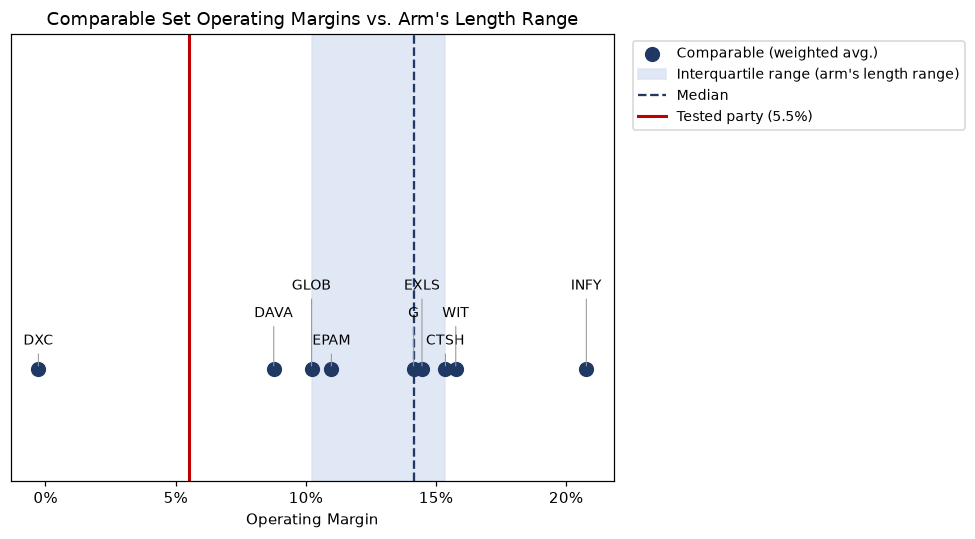

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

tickers = [t for t, _ in arms_length_range.values]
values = [v for _, v in arms_length_range.values]

ax.scatter(values, [0] * len(values), s=80, zorder=3, color="#1F3864", label="Comparable (weighted avg.)")
# Stagger label heights in a repeating pattern so tickers with close-together
# values (e.g. a cluster of comparables within a percentage point of each
# other) don't overlap into unreadable text.
_label_offsets = [16, 34, 52]
for i, (t, v) in enumerate(zip(tickers, values)):
    ax.annotate(
        t, (v, 0), xytext=(0, _label_offsets[i % len(_label_offsets)]),
        textcoords="offset points", ha="center", fontsize=9,
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.7),
    )

ax.axvspan(arms_length_range.q1, arms_length_range.q3, color="#D9E2F3", alpha=0.8,
           label="Interquartile range (arm's length range)")
ax.axvline(arms_length_range.median, color="#1F3864", linestyle="--", linewidth=1.5, label="Median")
ax.axvline(HYPOTHETICAL_TESTED_PARTY.operating_margin, color="#C00000", linewidth=2,
           label=f"Tested party ({HYPOTHETICAL_TESTED_PARTY.operating_margin:.1%})")

ax.set_yticks([])
ax.set_ylim(-0.6, 1.8)
ax.set_xlabel("Operating Margin")
ax.set_title("Comparable Set Operating Margins vs. Arm's Length Range")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
plt.tight_layout()
plt.show()

## 7. The Tested Party

The **tested party** is the entity in the controlled transaction whose result is
actually benchmarked — conventionally the less complex party, since a routine
functional profile is easier to find comparables for than a complex,
entrepreneurial one. This notebook uses a **fictional** hypothetical tested
party: a wholly-owned offshore IT service delivery subsidiary of a U.S. parent,
invented purely to illustrate the positioning and adjustment mechanics below.

In [9]:
tp = HYPOTHETICAL_TESTED_PARTY
print(f"Tested party: {tp.name}")
print(f"Fiscal year: {tp.fiscal_year}")
print(f"Revenue: ${tp.revenue:,.0f}")
print(f"Operating income: ${tp.operating_income:,.0f}")
print(f"Operating margin: {tp.operating_margin:.2%}")

positioning = assess_position(tp.operating_margin, arms_length_range)
print(f"\nArm's length range: {arms_length_range.q1:.2%} - {arms_length_range.q3:.2%}")
print(f"Position: {positioning.position.upper()}")

Tested party: TestCo Services Ltd. (hypothetical)
Fiscal year: 2025
Revenue: $80,000,000
Operating income: $4,400,000
Operating margin: 5.50%

Arm's length range: 10.23% - 15.37%
Position: BELOW RANGE


## 8. Primary Adjustment

Because the tested party's result falls **below** the arm's length range,
Treas. Reg. §1.482-1(e)(3) provides for a **primary adjustment**: absent a
showing that some other point in the range better reflects the controlled
transaction's facts, the result is adjusted to the range's **median** — not
merely nudged up to the nearest edge of the range. The adjustment below
computes the additional operating income (holding revenue fixed) needed to
bring the tested party's margin to the median.

In [10]:
adjustment = compute_primary_adjustment(tp, arms_length_range)

if adjustment is not None:
    print(f"Target margin (median): {adjustment.target_margin:.2%}")
    print(f"Target operating income: ${adjustment.target_operating_income:,.0f}")
    print(f"Actual operating income: ${tp.operating_income:,.0f}")
    print(f"Primary adjustment: ${adjustment.adjustment_amount:,.0f} ({adjustment.direction})")
else:
    print("Tested party result is within the arm's length range — no adjustment required.")

Target margin (median): 14.15%
Target operating income: $11,318,372
Actual operating income: $4,400,000
Primary adjustment: $6,918,372 (increase)


## 9. CUP Module — Intercompany Loan Interest Rate

As a second, simpler benchmarking exercise, this section prices a **fictional**
intercompany loan using the Comparable Uncontrolled Price method — comparing an
actual price (here, an interest rate) directly against comparable uncontrolled
pricing, rather than comparing overall profitability the way TNMM does. Following
the "yield curve + credit spread" approach the OECD Guidelines' Chapter X
describes for intra-group financing, the benchmark rate is built from:

1. A **live, public risk-free base rate** — the U.S. Treasury yield at the tenor
   matching the loan (via Yahoo Finance), and
2. A **credit spread** for the borrower's (assumed) credit rating.

The credit spread table is a static, illustrative set of typical
investment-grade/high-yield spread relationships — **not** a live market feed
(a real loan study would price the spread off current secondary-market bond or
loan data for issuers of matching rating and tenor). It's included to complete
the mechanic with at least one live public input, not to represent precise
current market spreads.

In [11]:
loan = HYPOTHETICAL_INTERCOMPANY_LOAN
loan_result = benchmark_loan_interest_rate(loan)

print(f"Loan principal: ${loan.principal:,.0f}")
print(f"Tenor: {loan.tenor}   Borrower credit rating (assumed): {loan.borrower_credit_rating}")
print(f"\nPublic risk-free rate (live Treasury pull): {loan_result.risk_free_rate:.2%}")
print(f"Illustrative credit spread: {loan_result.credit_spread_bps:.0f} bps")
print(f"Benchmark rate: {loan_result.benchmark_rate:.2%}")
print(f"\nActual intercompany rate: {loan.actual_annual_interest_rate:.2%}")
print(f"Difference: {loan_result.difference_bps:+.0f} bps")
print(f"Within ±{loan_result.tolerance_bps:.0f} bps tolerance: {loan_result.within_tolerance}")

Crumb fetch rate-limited (HTTP 429), continuing without crumb


Loan principal: $20,000,000
Tenor: 5-year   Borrower credit rating (assumed): BBB

Public risk-free rate (live Treasury pull): 4.85%
Illustrative credit spread: 150 bps
Benchmark rate: 6.35%

Actual intercompany rate: 4.50%
Difference: -185 bps
Within ±25 bps tolerance: False


The loan is priced well below its benchmark rate — a pattern that, in practice,
would understate the interest income (and taxable income) of the parent/lender
and warrant its own primary adjustment, mirroring the TNMM tested party's
below-range result above.

## 10. Generating the Benchmarking Report

The cell below assembles every exhibit above into a single formatted Excel
workbook — the kind of document that would actually be attached to a TP study:
a cover/summary page, the full screening log, per-year PLI detail, the arm's
length range with positioning, and the CUP loan analysis.

In [12]:
from datetime import date

tnmm_report_inputs = TnmmReportInputs(
    pli_name="operating_margin",
    screening_result=screening,
    annual_plis=annual_plis,
    weighted_plis=weighted_plis,
    arms_length_range=arms_length_range,
    tested_party=tp,
    positioning=positioning,
    primary_adjustment=adjustment,
)
report_inputs = ReportInputs(
    tnmm=tnmm_report_inputs,
    loan_benchmark=loan_result,
    as_of_date=date.today(),
    data_pull_date=pull_date,
)

output_path = write_report(report_inputs, Path("output/tp_benchmarking_report.xlsx"))
print(f"Report written to: {output_path} (relative to the project root)")

Report written to: output/tp_benchmarking_report.xlsx (relative to the project root)


## 11. Limitations & Disclaimer

**This notebook is an educational / methodology demonstration, not a real
economic analysis, comparability study, or tax/legal advice.** Specific
limitations, stated plainly rather than buried:

- **Data source.** Financial data comes from Yahoo Finance via `yfinance`, a
  free retail-investor-oriented feed, not a licensed commercial comparables
  database (S&P Capital IQ, Moody's Orbis/Bureau van Dijk, RoyaltyStat). Figures
  are normalized for retail consumption and have not been independently
  verified against each company's actual filed financial statements.
- **Related-party revenue screen.** Cannot be evaluated with public data at
  all — see Section 3. A comparable earning a material share of its revenue
  from related parties would not be excluded by this tool.
- **Candidate set construction.** Assembled from public industry knowledge
  rather than a queryable SIC/NAICS database, and is not exhaustive.
- **FX conversion.** A single static spot rate (as of the data-pull date) is
  used to convert non-USD comparables' revenue for the revenue-floor screen,
  rather than period-matched average rates. This does not affect the PLIs
  themselves, which are currency-invariant ratios.
- **CUP credit spread table.** Static and illustrative, not a live market
  data feed — see Section 9.
- **Tested party and intercompany loan.** Entirely fictional, invented to
  demonstrate the benchmarking mechanics, not derived from any real taxpayer's
  facts, functions, or risks.
- **No functional/risk analysis.** A real TNMM study begins with a detailed
  functional analysis (functions performed, assets used, risks assumed) of
  both the tested party and each comparable, which this tool does not attempt.

See `README.md` for the full project scope and disclaimer.